In [1]:
!pip install numpy pandas matplotlib seaborn scikit-learn

# Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics import confusion_matrix

# Load Iris Dataset

In [3]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add actual species
df["Species"] = iris.target

# Display first 5 rows
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Species  
0        0  
1        0  
2        0  
3        0  
4        0  


# Explore Dataset

In [4]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
print(df.info())

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check class distribution
print("\nSpecies Distribution:")
print(df["Species"].value_counts())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None

Statistical Summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000     

# Select Features

In [5]:
# Select input features
X = df.iloc[:, 0:4].values

# Actual labels for evaluation only
y = df["Species"].values

print("Feature Shape:", X.shape)
print("Label Shape:", y.shape)

Feature Shape: (150, 4)
Label Shape: (150,)


# Feature Scaling

In [6]:
# Initialize scaler
scaler = StandardScaler()

# Scale features
X_scaled = scaler.fit_transform(X)

print("Scaled Data:")
print(X_scaled[:5])

Scaled Data:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


# Initialize Fuzzy Membership Matrix

In [7]:
# Number of clusters
c = 3

# Fuzziness parameter
m = 2

# Number of data points
n = X_scaled.shape[0]

# Initialize random membership matrix
np.random.seed(42)

U = np.random.rand(n, c)

# Normalize membership values
U = U / np.sum(U, axis=1, keepdims=True)

print("Initial Membership Matrix:")
print(U[:5])

print("\nMembership Sum of First 5 Data Points:")
print(np.sum(U[:5], axis=1))

Initial Membership Matrix:
[[0.18205878 0.46212909 0.35581214]
 [0.65738127 0.17132261 0.17129612]
 [0.03807826 0.56784481 0.39407693]
 [0.41686469 0.01211874 0.57101657]
 [0.67865488 0.173111   0.14823412]]

Membership Sum of First 5 Data Points:
[1. 1. 1. 1. 1.]


# Calculate Cluster Centers

In [8]:
def calculate_centers(X, U, m):

    # Calculate membership power
    U_m = U ** m

    # Calculate cluster centers
    centers = np.dot(U_m.T, X) / np.sum(U_m, axis=0)[:, None]

    return centers

# Calculate Membership Matrix

In [9]:
def calculate_membership(X, centers, m):

    # Calculate distance between points and centers
    distances = np.zeros((X.shape[0], centers.shape[0]))

    for j in range(centers.shape[0]):

        distances[:, j] = np.linalg.norm(
            X - centers[j],
            axis=1
        )

    # Initialize membership matrix
    U_new = np.zeros_like(distances)

    # Handle zero distances
    for i in range(X.shape[0]):

        zero_indices = np.where(distances[i] == 0)[0]

        if len(zero_indices) > 0:

            U_new[i, zero_indices] = 1 / len(zero_indices)

        else:

            for j in range(centers.shape[0]):

                denominator = 0

                for k in range(centers.shape[0]):

                    denominator += (
                        distances[i, j] / distances[i, k]
                    ) ** (2 / (m - 1))

                U_new[i, j] = 1 / denominator

    return U_new

# Calculate Objective Function

In [10]:
def calculate_objective(X, U, centers, m):

    objective = 0

    for j in range(centers.shape[0]):

        distances = np.linalg.norm(
            X - centers[j],
            axis=1
        )

        objective += np.sum(
            (U[:, j] ** m) * (distances ** 2)
        )

    return objective

# Implement Fuzzy C-Means Algorithm

In [11]:
def fuzzy_c_means(X, c, m=2, max_iter=100, tol=0.0001):

    # Number of data points
    n = X.shape[0]

    # Random membership initialization
    np.random.seed(42)

    U = np.random.rand(n, c)

    U = U / np.sum(U, axis=1, keepdims=True)

    objective_history = []

    for iteration in range(max_iter):

        # Step 1: Calculate cluster centers
        centers = calculate_centers(X, U, m)

        # Step 2: Update membership matrix
        U_new = calculate_membership(X, centers, m)

        # Step 3: Calculate objective function
        objective = calculate_objective(
            X,
            U_new,
            centers,
            m
        )

        objective_history.append(objective)

        # Step 4: Check convergence
        difference = np.linalg.norm(U_new - U)

        if difference < tol:

            U = U_new

            print("Convergence reached!")

            print("Iterations:", iteration + 1)

            break

        # Update membership matrix
        U = U_new

    # Final cluster centers
    centers = calculate_centers(X, U, m)

    return centers, U, objective_history

# Train the Fuzzy C-Means Model

In [12]:
# Apply Fuzzy C-Means
centers, U, objective_history = fuzzy_c_means(
    X_scaled,
    c=3,
    m=2,
    max_iter=100,
    tol=0.0001
)

print("\nFinal Cluster Centers:")
print(centers)

print("\nFinal Membership Matrix:")
print(U[:10])

Convergence reached!
Iterations: 22

Final Cluster Centers:
[[ 1.06925529  0.03742924  0.97017835  1.02979466]
 [-0.03835579 -0.81871293  0.32297617  0.23215706]
 [-1.00478432  0.84648216 -1.28465352 -1.23864586]]

Final Membership Matrix:
[[3.13539184e-03 5.29728701e-03 9.91567321e-01]
 [5.18321515e-02 1.19203413e-01 8.28964435e-01]
 [2.33111247e-02 4.72979941e-02 9.29390881e-01]
 [4.12891236e-02 8.91743579e-02 8.69536519e-01]
 [1.00119929e-02 1.60494986e-02 9.73938508e-01]
 [7.92046149e-02 1.01999809e-01 8.18795576e-01]
 [1.43674269e-02 2.63413088e-02 9.59291264e-01]
 [6.12305653e-04 1.11418976e-03 9.98273505e-01]
 [7.90950939e-02 1.80581571e-01 7.40323335e-01]
 [3.44316745e-02 7.43490895e-02 8.91219236e-01]]


# Assign Data Points to Clusters

In [13]:
# Assign cluster based on highest membership
cluster_labels = np.argmax(U, axis=1)

# Add cluster labels to dataframe
df["FCM_Cluster"] = cluster_labels

print("Cluster Assignments:")
print(df[["Species", "FCM_Cluster"]].head(10))

Cluster Assignments:
   Species  FCM_Cluster
0        0            2
1        0            2
2        0            2
3        0            2
4        0            2
5        0            2
6        0            2
7        0            2
8        0            2
9        0            2


# Display Membership Degrees

In [14]:
# Create membership dataframe
membership_df = pd.DataFrame(
    U,
    columns=["Cluster_0", "Cluster_1", "Cluster_2"]
)

print("Membership Degrees:")
print(membership_df.head(10))

Membership Degrees:
   Cluster_0  Cluster_1  Cluster_2
0   0.003135   0.005297   0.991567
1   0.051832   0.119203   0.828964
2   0.023311   0.047298   0.929391
3   0.041289   0.089174   0.869537
4   0.010012   0.016049   0.973939
5   0.079205   0.102000   0.818796
6   0.014367   0.026341   0.959291
7   0.000612   0.001114   0.998274
8   0.079095   0.180582   0.740323
9   0.034432   0.074349   0.891219


In [15]:
# Combine original data and membership values
result_df = pd.concat(
    [df, membership_df],
    axis=1
)

print(result_df.head(10))

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

   Species  FCM_Cluster  Cluster_0  Cluster_1  Cluster_2  
0        0            2   0.003135   0.005297   0.991567  
1        0  

# Visualize Membership Degrees

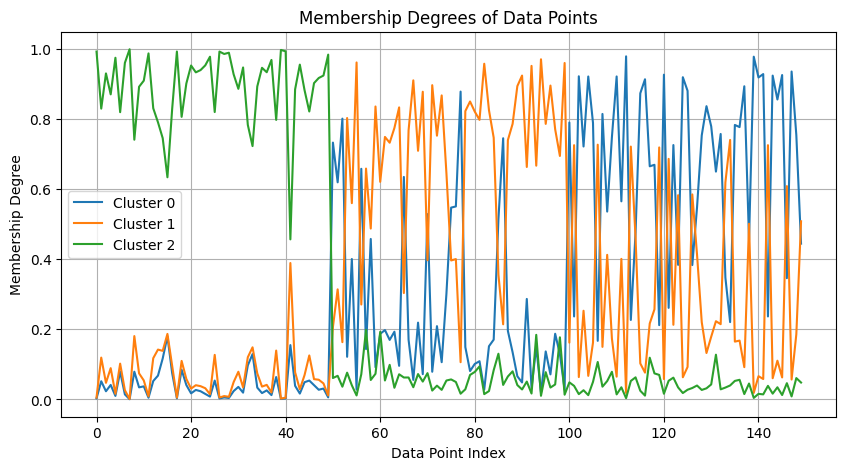

In [16]:
# Plot membership values
plt.figure(figsize=(10, 5))

plt.plot(U[:, 0], label="Cluster 0")
plt.plot(U[:, 1], label="Cluster 1")
plt.plot(U[:, 2], label="Cluster 2")

plt.title("Membership Degrees of Data Points")
plt.xlabel("Data Point Index")
plt.ylabel("Membership Degree")

plt.legend()
plt.grid(True)

plt.show()

# Visualize Clusters Using PCA

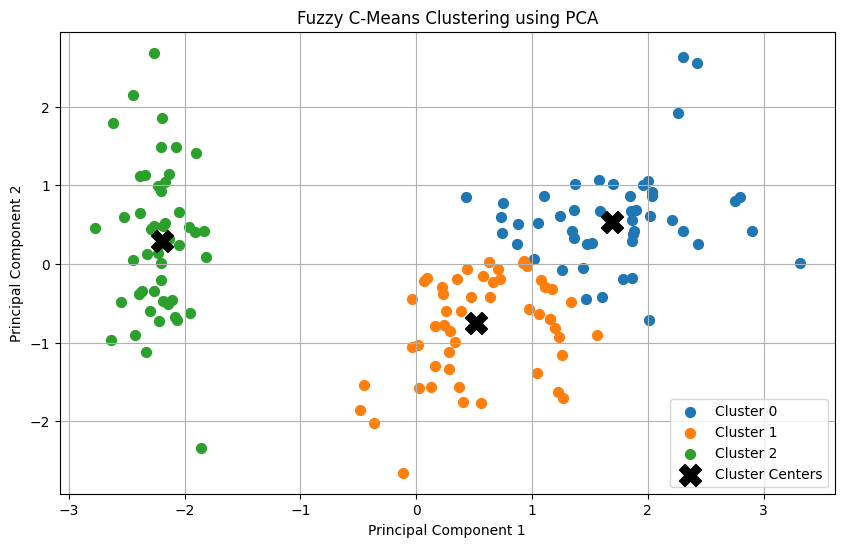

In [17]:
# Apply PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Transform cluster centers
centers_pca = pca.transform(centers)

# Plot clusters
plt.figure(figsize=(10, 6))

for i in range(c):

    plt.scatter(
        X_pca[cluster_labels == i, 0],
        X_pca[cluster_labels == i, 1],
        label=f"Cluster {i}",
        s=50
    )

# Plot cluster centers
plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Cluster Centers"
)

plt.title("Fuzzy C-Means Clustering using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(True)

plt.show()

# Plot Objective Function

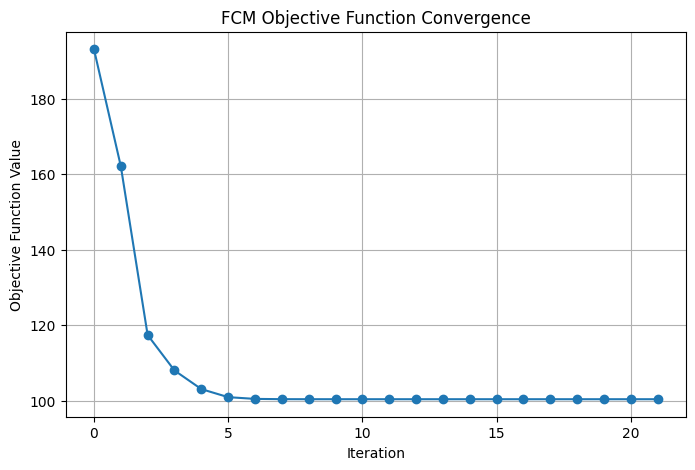

In [18]:
# Plot objective function
plt.figure(figsize=(8, 5))

plt.plot(
    objective_history,
    marker="o"
)

plt.title("FCM Objective Function Convergence")
plt.xlabel("Iteration")
plt.ylabel("Objective Function Value")

plt.grid(True)

plt.show()

Silhouette Score

In [19]:
# Calculate silhouette score
score = silhouette_score(
    X_scaled,
    cluster_labels
)

print("Silhouette Score:", score)

Silhouette Score: 0.45844171606773937


Compare Actual Species with Clusters

In [20]:
# Create comparison table
comparison = pd.crosstab(
    df["Species"],
    df["FCM_Cluster"],
    rownames=["Actual Species"],
    colnames=["Predicted Cluster"]
)

print(comparison)

Predicted Cluster   0   1   2
Actual Species               
0                   0   0  50
1                  11  39   0
2                  37  13   0


# Visualize Actual Species

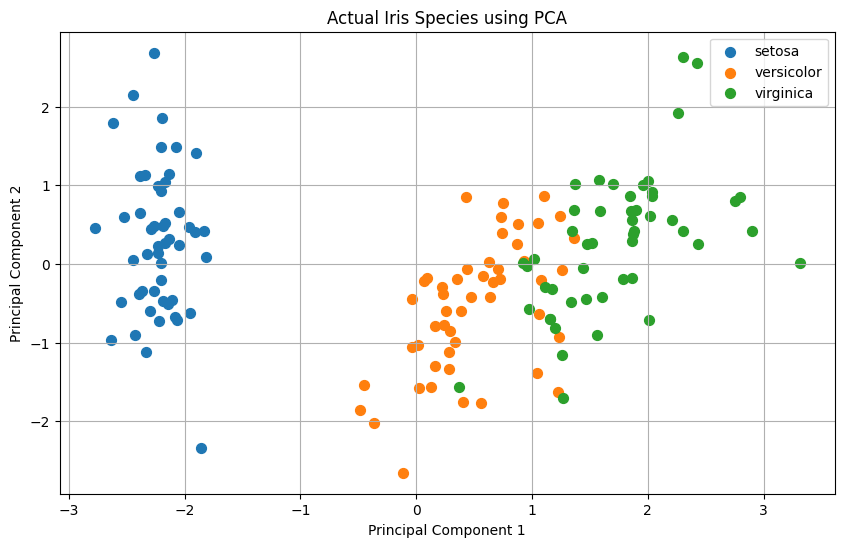

In [21]:
plt.figure(figsize=(10, 6))

for i in range(3):

    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=iris.target_names[i],
        s=50
    )

plt.title("Actual Iris Species using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(True)

plt.show()

# Display Final Results

In [22]:
# Cluster sizes
print("Cluster Sizes:")

print(pd.Series(cluster_labels).value_counts().sort_index())

# Silhouette score
print("\nSilhouette Score:", score)

# Number of iterations
print("\nTotal Iterations:", len(objective_history))

# Final objective function
print("\nFinal Objective Function:", objective_history[-1])

# Membership sum verification
print("\nMembership Sum Verification:")

print(np.sum(U, axis=1)[:10])

Cluster Sizes:
0    48
1    52
2    50
Name: count, dtype: int64

Silhouette Score: 0.45844171606773937

Total Iterations: 22

Final Objective Function: 100.420290209283

Membership Sum Verification:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]



# Fuzzy C-Means (FCM) Clustering

## Introduction

Fuzzy C-Means (FCM) is an unsupervised clustering algorithm used to group similar data points into different clusters.

Unlike K-Means, FCM allows a data point to belong to multiple clusters with different membership values. Each membership value represents how strongly a data point belongs to a particular cluster.

FCM is a type of **Soft Clustering** algorithm because it does not strictly assign each data point to only one cluster during the clustering process.

## Objective

- To understand the concept of Fuzzy C-Means clustering.
- To implement FCM using Python.
- To calculate membership values and cluster centers.
- To understand the role of the fuzziness parameter.
- To visualize clusters using PCA.
- To evaluate clustering performance using Silhouette Score.

## Dataset Description

In this experiment, the **Iris Dataset** is used to perform Fuzzy C-Means clustering.

The dataset contains 150 samples with four numerical features:

- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

It contains three actual species:

- Setosa
- Versicolor
- Virginica

For clustering, only the four numerical features are used. Actual species labels are used only for evaluation and comparison.

## Working Principle

FCM works by repeatedly updating membership values and cluster centers until the algorithm converges.

The main steps are:

- Select the number of clusters.
- Initialize the membership matrix randomly.
- Calculate cluster centers using membership values.
- Update membership values based on distances.
- Calculate the objective function.
- Check the convergence condition.
- Repeat the process until convergence.

## Membership Degree

Membership Degree represents how strongly a data point belongs to a particular cluster.

In FCM, each data point gets a membership value for every cluster. The membership value ranges from 0 to 1.

**Membership Condition:**

$$
0 \leq u_{ij} \leq 1
$$

The sum of membership values for each data point must be equal to 1.

$$
\sum_{j=1}^{c}u_{ij}=1
$$

Where:

- $u_{ij}$ = Membership value of data point $i$ in cluster $j$.
- $c$ = Number of clusters.

**Example:**

Suppose a data point has the following membership values:

| Cluster | Membership Value |
|---|---:|
| Cluster 1 | 0.20 |
| Cluster 2 | 0.70 |
| Cluster 3 | 0.10 |
| Total | 1.00 |

Here, Cluster 2 has the highest membership value. Therefore, the data point will be assigned to Cluster 2 when a final cluster label is required.

## Fuzziness Parameter (m)

The Fuzziness Parameter controls how soft the clustering will be.

- $m > 1$ is required.
- $m = 2$ is commonly used.
- A higher value of $m$ makes membership values more distributed among clusters.
- A value close to 1 makes the clustering more similar to hard clustering.

For this experiment, we use:

$$
m=2
$$

## Objective Function

FCM tries to minimize the objective function by updating membership values and cluster centers.

$$
J_m=\sum_{i=1}^{n}\sum_{j=1}^{c}u_{ij}^{m}d_{ij}^{2}
$$

Where:

- $J_m$ = Objective function.
- $n$ = Number of data points.
- $c$ = Number of clusters.
- $u_{ij}$ = Membership value.
- $m$ = Fuzziness parameter.
- $d_{ij}$ = Distance between a data point and a cluster center.

A lower objective function value indicates that data points are closer to their cluster centers according to their membership weights.

## Cluster Center Update

FCM calculates cluster centers using membership values as weights.

$$
v_j=
\frac{\sum_{i=1}^{n}u_{ij}^{m}x_i}
{\sum_{i=1}^{n}u_{ij}^{m}}
$$

Where:

- $v_j$ = Cluster center.
- $x_i$ = Data point.
- $u_{ij}$ = Membership value.
- $m$ = Fuzziness parameter.

Data points with higher membership values have more influence on the cluster center.

## Membership Update

FCM updates membership values based on the distances between data points and cluster centers.

$$
u_{ij}=
\frac{1}{
\sum_{k=1}^{c}
\left(
\frac{d_{ij}}{d_{ik}}
\right)^{\frac{2}{m-1}}
}
$$

A data point closer to a cluster center generally gets a higher membership value for that cluster. A point farther away gets a lower membership value.

## Feature Scaling

Feature scaling is important for FCM because it uses distance calculations to determine cluster membership.

StandardScaler is used to transform the features so that they have approximately zero mean and unit variance.

**Standardization Formula:**

$$
z=\frac{x-\mu}{\sigma}
$$

Where:

- $x$ = Original feature value.
- $\mu$ = Mean of the feature.
- $\sigma$ = Standard deviation.

## Algorithm Steps

- Select the number of clusters $c$.
- Set the fuzziness parameter $m$.
- Initialize the membership matrix randomly.
- Normalize the membership values so that their sum for each data point is 1.
- Calculate cluster centers using the membership matrix.
- Update membership values using the distances from cluster centers.
- Calculate the objective function.
- Check the convergence condition.
- Repeat the update steps until convergence or the maximum number of iterations is reached.
- Assign each data point to the cluster with the highest membership value.

## PCA Visualization

Principal Component Analysis (PCA) is used to reduce the four-dimensional Iris dataset into two dimensions for visualization.

PCA helps display the clusters in a 2D scatter plot.

The cluster centers are also transformed into two dimensions and displayed in the plot.

**Interpretation:**

- Each color represents a different cluster.
- Black X markers represent cluster centers.
- Nearby points generally have similar cluster assignments.
- Points near cluster boundaries may have membership in multiple clusters.

## Objective Function Convergence

The objective function is calculated during each iteration of FCM.

The algorithm continues updating membership values and cluster centers until the convergence condition is satisfied.

A decreasing objective function generally indicates that the clustering process is improving.

The convergence plot helps observe how the objective function changes across iterations.

## Silhouette Score

Silhouette Score is used to evaluate the quality of clustering.

Its value ranges from -1 to +1.

$$
-1 \leq S \leq 1
$$

- A score close to +1 indicates well-separated clusters.
- A score close to 0 indicates overlapping clusters.
- A negative score indicates that some data points may be assigned to inappropriate clusters.

In this experiment, Silhouette Score is calculated using the final cluster labels obtained from the highest membership values.

## Advantages

- Handles overlapping data points.
- Provides membership values for each cluster.
- Represents uncertainty in cluster assignments.
- Useful when cluster boundaries are not clearly separated.
- Provides flexible cluster membership.

## Limitations

- The number of clusters must be selected in advance.
- Results may depend on the initial membership matrix.
- Computationally slower than K-Means.
- Sensitive to noise and outliers.
- Requires a suitable fuzziness parameter.

## K-Means vs Fuzzy C-Means

| K-Means | Fuzzy C-Means |
|---|---|
| Hard clustering | Soft clustering |
| Each point belongs to one cluster | Each point can belong to multiple clusters |
| Membership is 0 or 1 | Membership ranges from 0 to 1 |
| Uses ordinary cluster centers | Uses membership-weighted cluster centers |
| Faster | Comparatively slower |

## Experimental Results

The Fuzzy C-Means algorithm was implemented on the Iris dataset with the following configuration:

| Parameter | Value |
|---|---|
| Dataset | Iris |
| Total Samples | 150 |
| Features | 4 |
| Number of Clusters | 3 |
| Fuzziness Parameter (m) | 2 |
| Maximum Iterations | 100 |
| Convergence Tolerance | 0.0001 |
| Feature Scaling | StandardScaler |
| Visualization | PCA (2D) |

**Observed Results:**

| Evaluation Metric | Result |
|---|---:|
| Total Iterations | 22 |
| Final Objective Function | 100.4203 |
| Silhouette Score | 0.4584 |

**Cluster Distribution:**

| Cluster | Number of Samples |
|---|---:|
| Cluster 0 | 48 |
| Cluster 1 | 52 |
| Cluster 2 | 50 |
| Total | 150 |

The membership sum verification also confirms that the membership values of each data point add up to approximately 1.

## Actual Species vs Predicted Clusters

The actual Iris species labels are compared with the predicted cluster labels using a cross-tabulation table.

| Actual Species | Cluster 0 | Cluster 1 | Cluster 2 |
|---|---:|---:|---:|
| Setosa (0) | 0 | 0 | 50 |
| Versicolor (1) | 11 | 39 | 0 |
| Virginica (2) | 37 | 13 | 0 |

This comparison shows that Setosa is clearly separated into one cluster, while Versicolor and Virginica have some overlap.

Note that cluster numbers are arbitrary and do not directly represent species labels.

## Conclusion

Fuzzy C-Means is a soft clustering algorithm that assigns membership values to data points for different clusters. Unlike K-Means, it allows a data point to belong to multiple clusters with different membership degrees.

In this experiment, FCM was successfully implemented on the Iris dataset using Python. The algorithm converged after 22 iterations and achieved a Silhouette Score of 0.4584.

Membership values, cluster centers, PCA visualization, objective function convergence, and cluster comparison were used to analyze the clustering performance.

The results show that FCM can identify clusters while representing the uncertainty and overlapping nature of data points.
